# Lecture 8 — Class Exercise
## Choropleth Maps

> **Push to:** `week08/lecture08_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


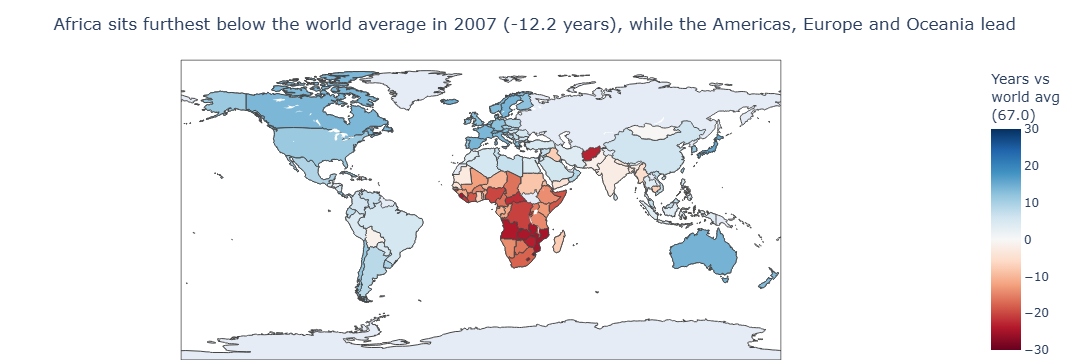

In [2]:
# Task 1

gm = px.data.gapminder()
gm_2007 = gm[gm['year'] == 2007].copy()

# Deviation from the global mean life expectancy
global_mean = gm_2007['lifeExp'].mean()
gm_2007['deviation'] = gm_2007['lifeExp'] - global_mean

# Find the region furthest below average (for the insight title)
region_dev = gm_2007.groupby('continent')['deviation'].mean()
worst_region = region_dev.idxmin()
worst_gap = region_dev.min()

fig1 = px.choropleth(
    gm_2007,
    locations='iso_alpha',
    color='deviation',
    hover_name='country',
    hover_data={'iso_alpha': False, 'lifeExp': ':.1f', 'deviation': ':+.1f'},
    color_continuous_scale='RdBu',      # diverging: red = below, blue = above
    color_continuous_midpoint=0,        # centred on the world average
    range_color=[-30, 30],              # symmetric range so 0 stays the midpoint
    labels={'lifeExp': 'Life expectancy (yrs)',
            'deviation': 'Deviation from world avg (yrs)'},
    title=(f'{worst_region} sits furthest below the world average in 2007 '
           f'({worst_gap:+.1f} years), while the Americas, Europe and Oceania lead')
)
fig1.update_layout(
    margin=dict(l=0, r=0, t=60, b=0),
    coloraxis_colorbar=dict(title='Years vs<br>world avg<br>(%.1f)' % global_mean)
)
fig1.show()


## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json

**Chart type chosen** (`px.choropleth` or `px.choropleth_mapbox`) **and reason:**

*Your answer here* 

px.choropleth_map:- It gives a zoomable, pannable basemap that is easy to read at state level. It is also the current replacement for the deprecated choropleth_mapbox, and it needs no access token with the carto-positron style


**Colour scale chosen** (sequential or diverging) **and reason:**

*Your answer here* 

Sequential (YlOrRd), because density only goes from low to high and has no meaningful midpoint. I plot log10(density) because density is extremely skewed (DC is over 10,000 per sq mi, Alaska about 1).


{'name': 'Alabama', 'density': 94.65}


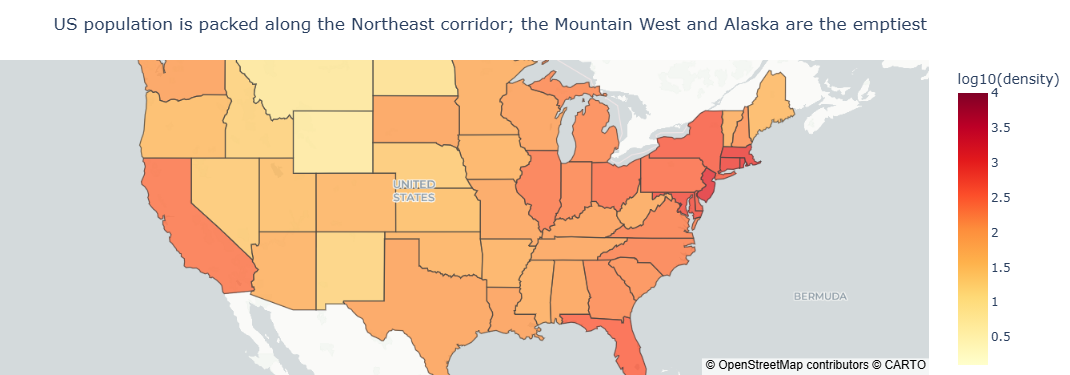

In [5]:
# Task 2

import numpy as np
import requests

url = ('https://raw.githubusercontent.com/PublicaMundi/MappingAPI/'
       'master/data/geojson/us-states.json')
my_geojson = requests.get(url).json()

# Inspect properties to find the right featureidkey
print(my_geojson['features'][0]['properties'])
# -> {'name': 'Alabama', 'density': 94.65}

# Build a dataframe from the GeoJSON properties (one numeric value per region)
df_us = pd.DataFrame([f['properties'] for f in my_geojson['features']])
df_us = df_us.rename(columns={'name': 'state'})
df_us['log_density'] = np.log10(df_us['density'])

fig2 = px.choropleth_map(
    df_us,
    geojson=my_geojson,
    locations='state',
    featureidkey='properties.name',     # matches df 'state' column
    color='log_density',
    hover_name='state',
    hover_data={'density': ':.1f', 'log_density': False, 'state': False},
    color_continuous_scale='YlOrRd',    # sequential
    map_style='carto-positron',
    center={'lat': 38, 'lon': -96},
    zoom=3,
    opacity=0.75,
    labels={'density': 'People per sq mi', 'log_density': 'log10(density)'},
    title='US population is packed along the Northeast corridor; '
          'the Mountain West and Alaska are the emptiest'
)
fig2.update_layout(margin=dict(l=0, r=0, t=60, b=0))
fig2.show()
